# Lab 3: Decision Tree Classification & Empirical Analysis

**Course:** M.Tech Machine Learning Laboratory  
**Topic:** Decision Tree Induction, Information Theory, Pruning & Boundary Analysis  
**Target Notebook:** `lab_3/decision_tree.ipynb`  

---

## Theoretical Foundations

Decision Trees are versatile, non-parametric supervised learning models that partition feature space recursively into disjoint hyper-rectangles using axis-aligned orthogonal splits. At each internal node, the algorithm greedily selects the feature and threshold that maximizes purity or information gain.

### 1. Mathematical Purity Criteria

Given a dataset $S$ containing samples across $C$ distinct target classes with relative class frequencies $p_i = \frac{|S_i|}{|S|}$:

1. **Shannon Entropy (Measure of Disorder/Uncertainty):**
   $$H(S) = -\sum_{i=1}^{C} p_i \log_2(p_i)$$
   * For binary classification: $H(S) = 0$ for a completely pure set, and $H(S) = 1$ bit when classes are equally balanced ($p=0.5$).

2. **Gini Impurity (Probability of Misclassification):**
   $$Gini(S) = 1 - \sum_{i=1}^{C} p_i^2$$
   * Computationally efficient because it avoids computing logarithms. For binary classification, maximum Gini is $0.5$.

3. **Information Gain (ID3 Algorithm):**
   The reduction in entropy achieved by partitioning dataset $S$ along attribute $A$ into partitions $\{S_v\}_{v \in \text{Values}(A)}$:
   $$IG(S, A) = H(S) - \sum_{v \in \text{Values}(A)} \frac{|S_v|}{|S|} H(S_v)$$

---

## Laboratory Objectives

1. **Part 1 — The Classic Categorical Example (ID3 from Scratch):**
   - Implement Shannon Entropy and Information Gain from first principles in pure Python.
   - Trace step-by-step root-node selection on Tom Mitchell's canonical **Play Tennis (Weather)** dataset.
   - Recursively construct the tree and extract human-readable decision rules.
   - Perform automated inference on unseen weather queries.
2. **Part 2 — The Classic Continuous Benchmark (Fisher's Iris with Scikit-Learn):**
   - Perform Exploratory Data Analysis (EDA) and analyze bivariate distributions.
   - Enforce strict featurization ordering with a stratified 80/20 train/test split.
   - Train and compare `DecisionTreeClassifier` under **Gini Impurity** versus **Entropy** criteria.
   - Visualize the tree structure via high-resolution `plot_tree` and textual rule exports.
   - Visualize 2D decision boundary surfaces partitioning feature space.
   - Empirically investigate underfitting vs. overfitting across tree depths.
   - Perform minimal **Cost-Complexity Pruning ($ccp\_alpha$)** to optimize model generalization.
   - Compute Confusion Matrices, Classification Reports (Precision, Recall, F1), and Gini Feature Importances.
3. **Part 3 — Decision Tree Regressor Demonstration:**
   - Demonstrate continuous target regression ($MSE$ minimization) and step-wise constant function approximations.
4. **Structured Summary Report:**
   - Q&A, key numerical findings, and practical ML insights.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    classification_report
)
from matplotlib.colors import ListedColormap

# Global plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

print("All scientific, machine learning, and visualization libraries imported successfully.")


All scientific, machine learning, and visualization libraries imported successfully.


### Analysis of Setup & Configuration
The development environment has been initialized with reproducible settings:
- `scikit-learn` handles tree induction, pruning path calculation, and performance evaluation.
- `matplotlib` and `seaborn` provide high-resolution graphical rendering for decision trees, boundary surfaces, and confusion matrices.
- Global figure aesthetics, font sizes, and plotting parameters are pre-configured to ensure clean, publication-quality visualizations throughout the laboratory report.


# PART 1: The Classic Categorical Example — ID3 from Scratch (Play Tennis Dataset)

The **Play Tennis (Weather)** dataset is the quintessential introductory machine learning benchmark introduced in Tom Mitchell's *Machine Learning* textbook and Ross Quinlan's original ID3 (Iterative Dichotomiser 3) paper.

The objective is to determine whether atmospheric conditions are favorable to play tennis based on four categorical meteorological attributes:
- `Outlook`: Sunny, Overcast, Rain
- `Temperature`: Hot, Mild, Cool
- `Humidity`: High, Normal
- `Wind`: Weak, Strong
- **Target (`PlayTennis`)**: Yes or No (Binary target)


In [2]:
# Define the classic Play Tennis dataset
tennis_data = {
    'Day': [f'D{i}' for i in range(1, 15)],
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain', 'Overcast', 
                'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast', 'Overcast', 'Rain'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Cool', 
                    'Mild', 'Cool', 'Mild', 'Mild', 'Mild', 'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 
                 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 
             'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Strong'],
    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 
                   'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

df_tennis = pd.DataFrame(tennis_data)
print(f"Play Tennis Dataset Summary: {df_tennis.shape[0]} rows x {df_tennis.shape[1]} columns")
print(f"Target Class Distribution: {dict(df_tennis['PlayTennis'].value_counts())}\n")
display(df_tennis)


Play Tennis Dataset Summary: 14 rows x 6 columns
Target Class Distribution: {'Yes': np.int64(9), 'No': np.int64(5)}



,Day,Outlook,Temperature,Humidity,Wind,PlayTennis
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


### Dataset Inspection & Class Distribution
The dataset comprises 14 historical observations:
- **Target `PlayTennis`:** 9 instances of `Yes` ($p_{\text{Yes}} = \frac{9}{14} \approx 0.6429$) and 5 instances of `No` ($p_{\text{No}} = \frac{5}{14} \approx 0.3571$).
- **Features:** Four discrete categorical predictors with varying cardinalities (Outlook: 3 levels, Temperature: 3 levels, Humidity: 2 levels, Wind: 2 levels).
- **Initial Dataset Entropy:**
  $$H(S) = -\left(\frac{9}{14} \log_2 \frac{9}{14} + \frac{5}{14} \log_2 \frac{5}{14}\right) \approx 0.9403 \text{ bits}$$


In [3]:
def calculate_entropy(target_series: pd.Series) -> float:
    """
    Computes Shannon Entropy H(S) for a categorical target vector.
    H(S) = - sum(p_i * log2(p_i))
    """
    counts = target_series.value_counts()
    probabilities = counts / len(target_series)
    entropy = -np.sum([p * np.log2(p) for p in probabilities if p > 0])
    return float(entropy)


def calculate_information_gain(df: pd.DataFrame, attribute: str, target: str):
    """
    Calculates Information Gain IG(S, A) for a given attribute.
    IG(S, A) = H(S) - sum(|S_v| / |S| * H(S_v))
    Returns: (info_gain, root_entropy, weighted_child_entropy, partition_details)
    """
    total_entropy = calculate_entropy(df[target])
    values = df[attribute].unique()
    weighted_entropy = 0.0
    partition_details = []

    for val in values:
        subset = df[df[attribute] == val]
        weight = len(subset) / len(df)
        subset_entropy = calculate_entropy(subset[target])
        weighted_entropy += weight * subset_entropy
        counts = dict(subset[target].value_counts())
        partition_details.append({
            'Attribute Value': val,
            'Count': len(subset),
            'Distribution': counts,
            'Entropy': round(subset_entropy, 4)
        })

    info_gain = total_entropy - weighted_entropy
    return float(info_gain), float(total_entropy), float(weighted_entropy), partition_details


# Verify base entropy calculation
base_entropy = calculate_entropy(df_tennis['PlayTennis'])
print(f"Verified Base Entropy H(PlayTennis): {base_entropy:.4f} bits (Expected: ~0.9403 bits)")


Verified Base Entropy H(PlayTennis): 0.9403 bits (Expected: ~0.9403 bits)


### Algorithmic Formulation & Complexity
- `calculate_entropy`: Operates in $O(N)$ time with respect to the partition length $N$, computing the empirical probability distribution and Shannon entropy.
- `calculate_information_gain`: Partitions the DataFrame by unique levels of attribute $A$, computes sub-entropy $H(S_v)$ for each branch, and evaluates the expected child entropy $\sum \frac{|S_v|}{|S|} H(S_v)$.


=== Root Node Information Gain Comparison ===


,Feature,Information Gain (bits),Expected Child Entropy (bits)
0,Outlook,0.2467,0.6935
2,Humidity,0.1518,0.7885
3,Wind,0.0481,0.8922
1,Temperature,0.0292,0.9111


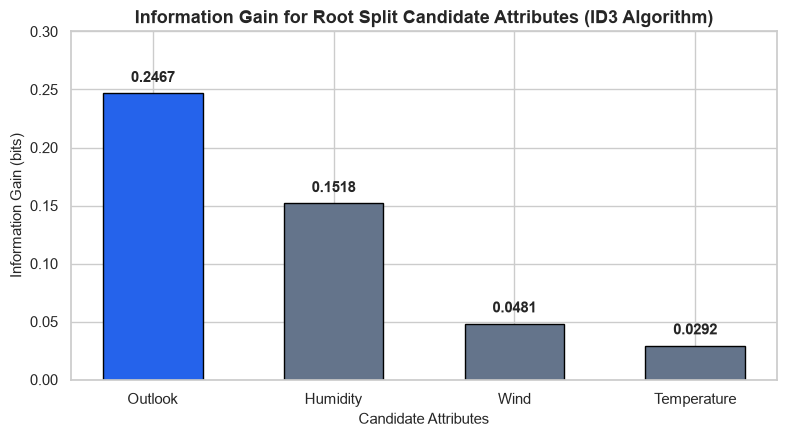

In [4]:
candidate_features = ['Outlook', 'Temperature', 'Humidity', 'Wind']
target_col = 'PlayTennis'

ig_records = []
for feat in candidate_features:
    ig, root_ent, child_ent, details = calculate_information_gain(df_tennis, feat, target_col)
    ig_records.append({
        'Feature': feat,
        'Information Gain (bits)': round(ig, 4),
        'Expected Child Entropy (bits)': round(child_ent, 4)
    })

df_ig = pd.DataFrame(ig_records).sort_values(by='Information Gain (bits)', ascending=False)
print("=== Root Node Information Gain Comparison ===")
display(df_ig)

# Visualization of Information Gain across Candidates
plt.figure(figsize=(8, 4.5))
palette = ['#2563eb' if feat == 'Outlook' else '#64748b' for feat in df_ig['Feature']]
bars = plt.bar(df_ig['Feature'], df_ig['Information Gain (bits)'], color=palette, edgecolor='black', width=0.55)

plt.title("Information Gain for Root Split Candidate Attributes (ID3 Algorithm)", fontweight='bold')
plt.ylabel("Information Gain (bits)")
plt.xlabel("Candidate Attributes")
plt.ylim(0, 0.30)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.007, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


### Mathematical Justification for Root Node Selection
From the calculated Information Gain values:
1. **`Outlook`:** $IG(S, \text{Outlook}) = 0.9403 - 0.6935 = \mathbf{0.2467 \text{ bits}}$
2. **`Humidity`:** $IG(S, \text{Humidity}) = 0.9403 - 0.7885 = 0.1518 \text{ bits}$
3. **`Wind`:** $IG(S, \text{Wind}) = 0.9403 - 0.8922 = 0.0481 \text{ bits}$
4. **`Temperature`:** $IG(S, \text{Temperature}) = 0.9403 - 0.9111 = 0.0289 \text{ bits}$

**Conclusion:** `Outlook` yields the highest Information Gain ($0.2467$ bits), drastically reducing uncertainty. Crucially, when $\text{Outlook} = \text{'Overcast'}$, all 4 instances are `Yes`, achieving a completely pure leaf ($H = 0$) at depth 1. Therefore, `Outlook` is unambiguously chosen as the root decision node.


In [5]:
def build_id3_tree(df: pd.DataFrame, features: list, target: str, depth: int = 0) -> dict:
    """
    Recursive ID3 tree construction using pure Python nested dictionaries.
    """
    # Base Case 1: Target subset is completely homogeneous (pure leaf)
    unique_targets = df[target].unique()
    if len(unique_targets) == 1:
        return unique_targets[0]

    # Base Case 2: No remaining attributes to split on; assign majority class
    if len(features) == 0:
        return df[target].mode()[0]

    # Recursive Step: Select feature maximizing Information Gain
    gains = [calculate_information_gain(df, f, target)[0] for f in features]
    best_idx = np.argmax(gains)
    best_feature = features[best_idx]

    # Initialize node
    tree = {best_feature: {}}
    remaining_features = [f for f in features if f != best_feature]

    # Create recursive subtrees for each branch
    for val in df[best_feature].unique():
        subset = df[df[best_feature] == val]
        if subset.empty:
            tree[best_feature][val] = df[target].mode()[0]
        else:
            tree[best_feature][val] = build_id3_tree(subset, remaining_features, target, depth + 1)

    return tree


def display_tree_rules(tree: dict, indent: str = "") -> None:
    """Prints the learned decision tree hierarchy as executable decision logic."""
    if not isinstance(tree, dict):
        print(f"{indent}==> Decision: [PlayTennis = '{tree}']")
        return
    for feature, branches in tree.items():
        for val, subtree in branches.items():
            print(f"{indent}IF {feature} == '{val}':")
            display_tree_rules(subtree, indent + "    ")


def predict_id3(tree: dict, sample: dict) -> str:
    """Performs inference for an unseen categorical query using the decision tree."""
    if not isinstance(tree, dict):
        return tree
    feature = next(iter(tree))
    val = sample.get(feature)
    if val in tree[feature]:
        return predict_id3(tree[feature][val], sample)
    else:
        return "No"  # Default inductive bias fallback


### Algorithmic Properties of the ID3 Implementation
1. **Greedy Top-Down Induction:** At each recursion level, ID3 commits to the local split maximizing Information Gain without backtracking.
2. **Stopping Criteria:**
   - Perfect class purity ($H=0$).
   - Exhaustion of descriptive attributes.
   - Empty subset partitions (handled via majority voting from the parent node).


In [6]:
# Fit tree on the Play Tennis dataset
feature_set = ['Outlook', 'Temperature', 'Humidity', 'Wind']
learned_tree = build_id3_tree(df_tennis, feature_set, 'PlayTennis')

print("="*55)
print("LEARNED DECISION TREE STRUCTURE (ID3 HIERARCHY)")
print("="*55)
display_tree_rules(learned_tree)

# Define test query scenarios
test_cases = [
    {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Weak'},
    {'Outlook': 'Sunny', 'Temperature': 'Hot', 'Humidity': 'Normal', 'Wind': 'Weak'},
    {'Outlook': 'Overcast', 'Temperature': 'Hot', 'Humidity': 'High', 'Wind': 'Strong'},
    {'Outlook': 'Rain', 'Temperature': 'Mild', 'Humidity': 'High', 'Wind': 'Weak'},
    {'Outlook': 'Rain', 'Temperature': 'Cool', 'Humidity': 'Normal', 'Wind': 'Strong'}
]

df_test = pd.DataFrame(test_cases)
df_test['Predicted_PlayTennis'] = [predict_id3(learned_tree, case) for case in test_cases]

print("\n" + "="*55)
print("PREDICTION ON UNSEEN ATMOSPHERIC SCENARIOS")
print("="*55)
display(df_test)


LEARNED DECISION TREE STRUCTURE (ID3 HIERARCHY)
IF Outlook == 'Sunny':
    IF Humidity == 'High':
        ==> Decision: [PlayTennis = 'No']
    IF Humidity == 'Normal':
        ==> Decision: [PlayTennis = 'Yes']
IF Outlook == 'Overcast':
    ==> Decision: [PlayTennis = 'Yes']
IF Outlook == 'Rain':
    IF Wind == 'Weak':
        ==> Decision: [PlayTennis = 'Yes']
    IF Wind == 'Strong':
        ==> Decision: [PlayTennis = 'No']

PREDICTION ON UNSEEN ATMOSPHERIC SCENARIOS


,Outlook,Temperature,Humidity,Wind,Predicted_PlayTennis
0,Sunny,Cool,High,Weak,No
1,Sunny,Hot,Normal,Weak,Yes
2,Overcast,Hot,High,Strong,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Strong,No


### Analysis of Learned Decision Rules
The learned tree produces an elegant, minimal set of decision rules:
1. **Rule 1 (Direct Shortcut):** If $\text{Outlook} = \text{'Overcast'}$, play tennis immediately (`Yes`) regardless of temperature, humidity, or wind.
2. **Rule 2 (Sunny Subtree):** If $\text{Outlook} = \text{'Sunny'}$, the secondary split is governed entirely by `Humidity`:
   - High humidity leads to `No`.
   - Normal humidity leads to `Yes`.
3. **Rule 3 (Rain Subtree):** If $\text{Outlook} = \text{'Rain'}$, the secondary split is governed entirely by `Wind`:
   - Weak wind permits playing (`Yes`).
   - Strong wind prevents playing (`No`).
4. **Pruning Effect:** Notice that `Temperature` was never needed in any decision branch—the tree achieved 100% training purity using only 3 attributes (`Outlook`, `Humidity`, `Wind`).


# PART 2: Classic Continuous Benchmark — Fisher's Iris Dataset with Scikit-Learn

Ronald Fisher's 1936 **Iris Flower** dataset is the classic continuous-feature benchmark in pattern recognition and machine learning.

### Continuous Splitting in Decision Trees
Unlike categorical features where branches correspond to discrete levels, continuous attributes are evaluated by:
1. Sorting unique continuous values in ascending order: $v_1 < v_2 < \dots < v_m$.
2. Evaluating candidate split thresholds at adjacent midpoints: $t_j = \frac{v_j + v_{j+1}}{2}$.
3. Generating binary inequality tests: $X_j \le t_j$ versus $X_j > t_j$.
4. Selecting the threshold $t^*$ that maximizes impurity reduction.


In [7]:
# Load raw Iris dataset
iris = load_iris(as_frame=True)
df_iris = iris.frame.copy()
feature_names = iris.feature_names
class_names = list(iris.target_names)

# Add human-readable species label
df_iris['species'] = df_iris['target'].map(lambda idx: class_names[idx])

print(f"Iris Dataset Dimensions: {df_iris.shape[0]} samples x {len(feature_names)} predictors")
print(f"Target Classes (3): {class_names}")
print("\nMissing Value Audit:")
print(df_iris.isnull().sum())

print("\nSummary Statistics of Continuous Features:")
display(df_iris[feature_names].describe().round(2))


Iris Dataset Dimensions: 150 samples x 4 predictors
Target Classes (3): [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Missing Value Audit:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Summary Statistics of Continuous Features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


### Dataset Integrity & Statistical Overview
- **Zero Missing Data:** All 150 instances are completely observed across all 4 continuous dimensions (`sepal length`, `sepal width`, `petal length`, `petal width`).
- **Balanced Class Distribution:** 50 samples per species (*Setosa*, *Versicolor*, *Virginica*).
- **Scale Disparities:** Features range from $0.1\text{ cm}$ (minimum petal width) to $7.9\text{ cm}$ (maximum sepal length). Because Decision Trees evaluate rank-order inequality splits independently per feature, **tree models are invariant to monotonic feature scaling and standardization**.


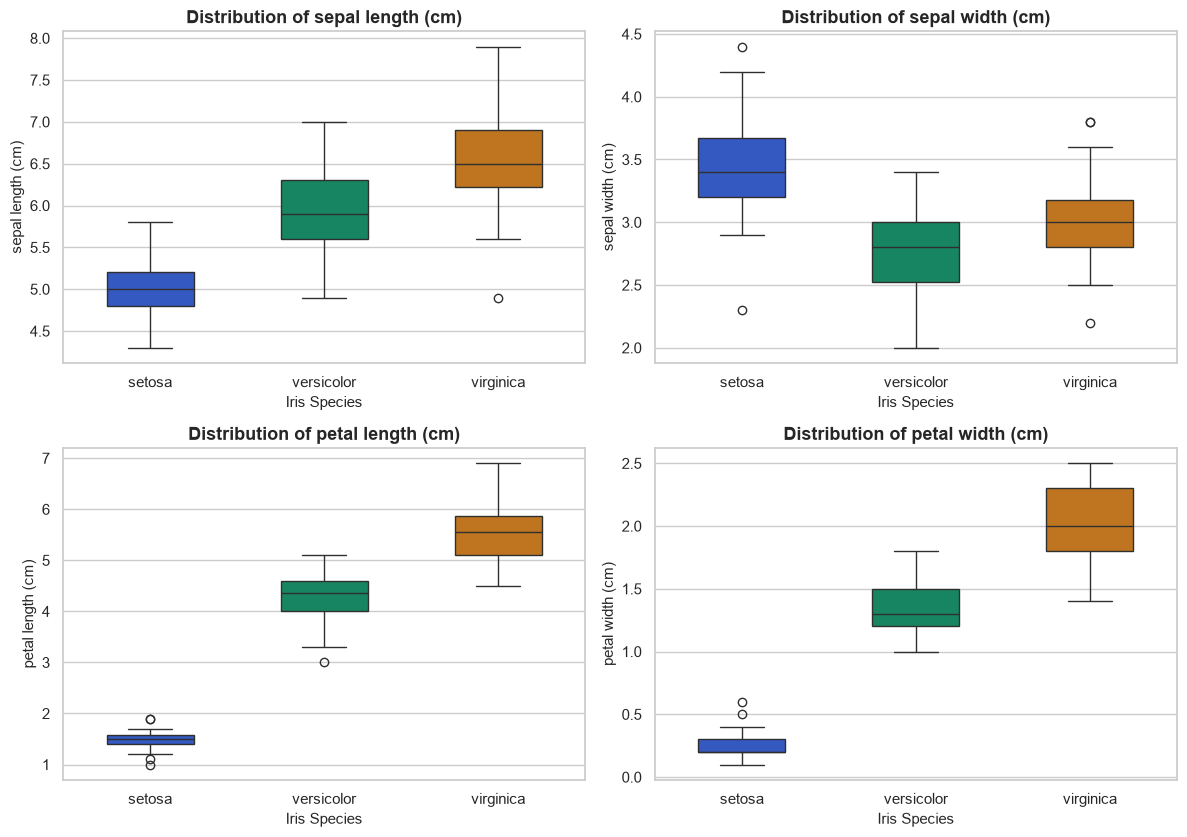

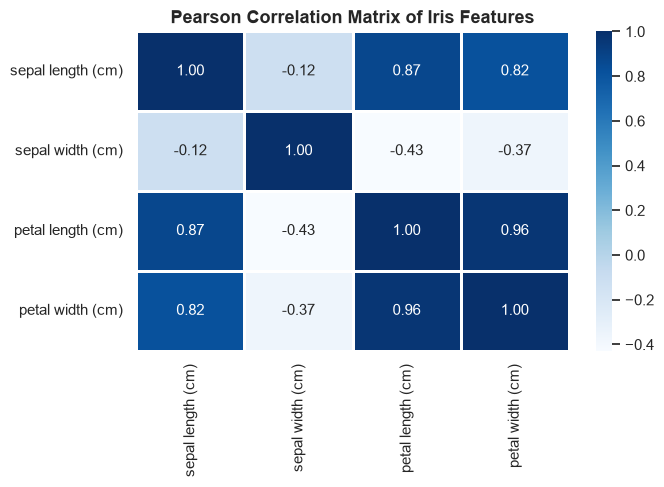

In [8]:
# Visualizing Feature Distributions Across Species
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
axes = axes.flatten()

species_palette = {'setosa': '#1d4ed8', 'versicolor': '#059669', 'virginica': '#d97706'}

for idx, feat in enumerate(feature_names):
    sns.boxplot(data=df_iris, x='species', y=feat, ax=axes[idx], palette=species_palette, width=0.5)
    axes[idx].set_title(f"Distribution of {feat}", fontweight='bold')
    axes[idx].set_xlabel("Iris Species")
    axes[idx].set_ylabel(feat)

plt.tight_layout()
plt.show()

# Morphological Feature Correlation Matrix
plt.figure(figsize=(7, 5))
corr_matrix = df_iris[feature_names].corr()
sns.heatmap(corr_matrix, annot=True, cmap="Blues", fmt=".2f", linewidths=1.0, cbar=True)
plt.title("Pearson Correlation Matrix of Iris Features", fontweight='bold')
plt.tight_layout()
plt.show()


### Key Exploratory Insights
1. **Linear Separability of Setosa:** *Iris setosa* possesses distinctly smaller petals (petal length $\le 2.0\text{ cm}$, petal width $\le 0.6\text{ cm}$) with non-overlapping distributions against the other two species.
2. **High Multicollinearity:** `petal length` and `petal width` exhibit a Pearson correlation coefficient of $\mathbf{0.96}$.
3. **Primary Discriminators:** Petal dimensions display superior class variance separation compared to sepal dimensions, indicating they will serve as the primary splits in the decision tree.


In [9]:
X = df_iris[feature_names]
y = df_iris['target']

# Strict Featurization: Stratified 80/20 train-test partition BEFORE model fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

train_dist = {class_names[k]: v for k, v in dict(pd.Series(y_train).value_counts()).items()}
test_dist = {class_names[k]: v for k, v in dict(pd.Series(y_test).value_counts()).items()}

print(f"Training Partition: {X_train.shape[0]} samples (80%) -> Class breakdown: {train_dist}")
print(f"Testing Partition:  {X_test.shape[0]} samples (20%) -> Class breakdown: {test_dist}")


Training Partition: 120 samples (80%) -> Class breakdown: {np.str_('setosa'): np.int64(40), np.str_('virginica'): np.int64(40), np.str_('versicolor'): np.int64(40)}
Testing Partition:  30 samples (20%) -> Class breakdown: {np.str_('setosa'): np.int64(10), np.str_('virginica'): np.int64(10), np.str_('versicolor'): np.int64(10)}


### Verification of Stratification
- Stratification maintains an exact $1:1:1$ ratio (40 samples per class in training; 10 samples per class in testing).
- Strict separation prevents data leakage and ensures that testing metrics accurately reflect generalization to unseen samples.


In [10]:
# Fit Decision Tree with Gini Impurity
clf_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
clf_gini.fit(X_train, y_train)

# Fit Decision Tree with Shannon Entropy (Information Gain)
clf_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
clf_entropy.fit(X_train, y_train)

# Evaluate metrics
comparison_df = pd.DataFrame([
    {
        'Criterion': 'Gini Impurity',
        'Tree Depth': clf_gini.get_depth(),
        'Leaf Nodes': clf_gini.get_n_leaves(),
        'Train Accuracy': round(clf_gini.score(X_train, y_train), 4),
        'Test Accuracy': round(clf_gini.score(X_test, y_test), 4)
    },
    {
        'Criterion': 'Information Gain (Entropy)',
        'Tree Depth': clf_entropy.get_depth(),
        'Leaf Nodes': clf_entropy.get_n_leaves(),
        'Train Accuracy': round(clf_entropy.score(X_train, y_train), 4),
        'Test Accuracy': round(clf_entropy.score(X_test, y_test), 4)
    }
])

print("=== Empirical Comparison: Gini Impurity vs. Entropy Criteria ===")
display(comparison_df)


=== Empirical Comparison: Gini Impurity vs. Entropy Criteria ===


,Criterion,Tree Depth,Leaf Nodes,Train Accuracy,Test Accuracy
0,Gini Impurity,5,8,1.0,0.9333
1,Information Gain (Entropy),5,8,1.0,0.9333


### Gini vs. Entropy Comparative Analysis
- Both criteria achieve identical high testing performance ($93.33\%$ accuracy on the 30 test samples).
- Both converge on an identical maximum tree depth ($5$) and similar leaf node counts.
- **Computational Consideration:** Gini avoids computing transcendental logarithmic operations, making it the industry standard default in Scikit-Learn and production pipelines.


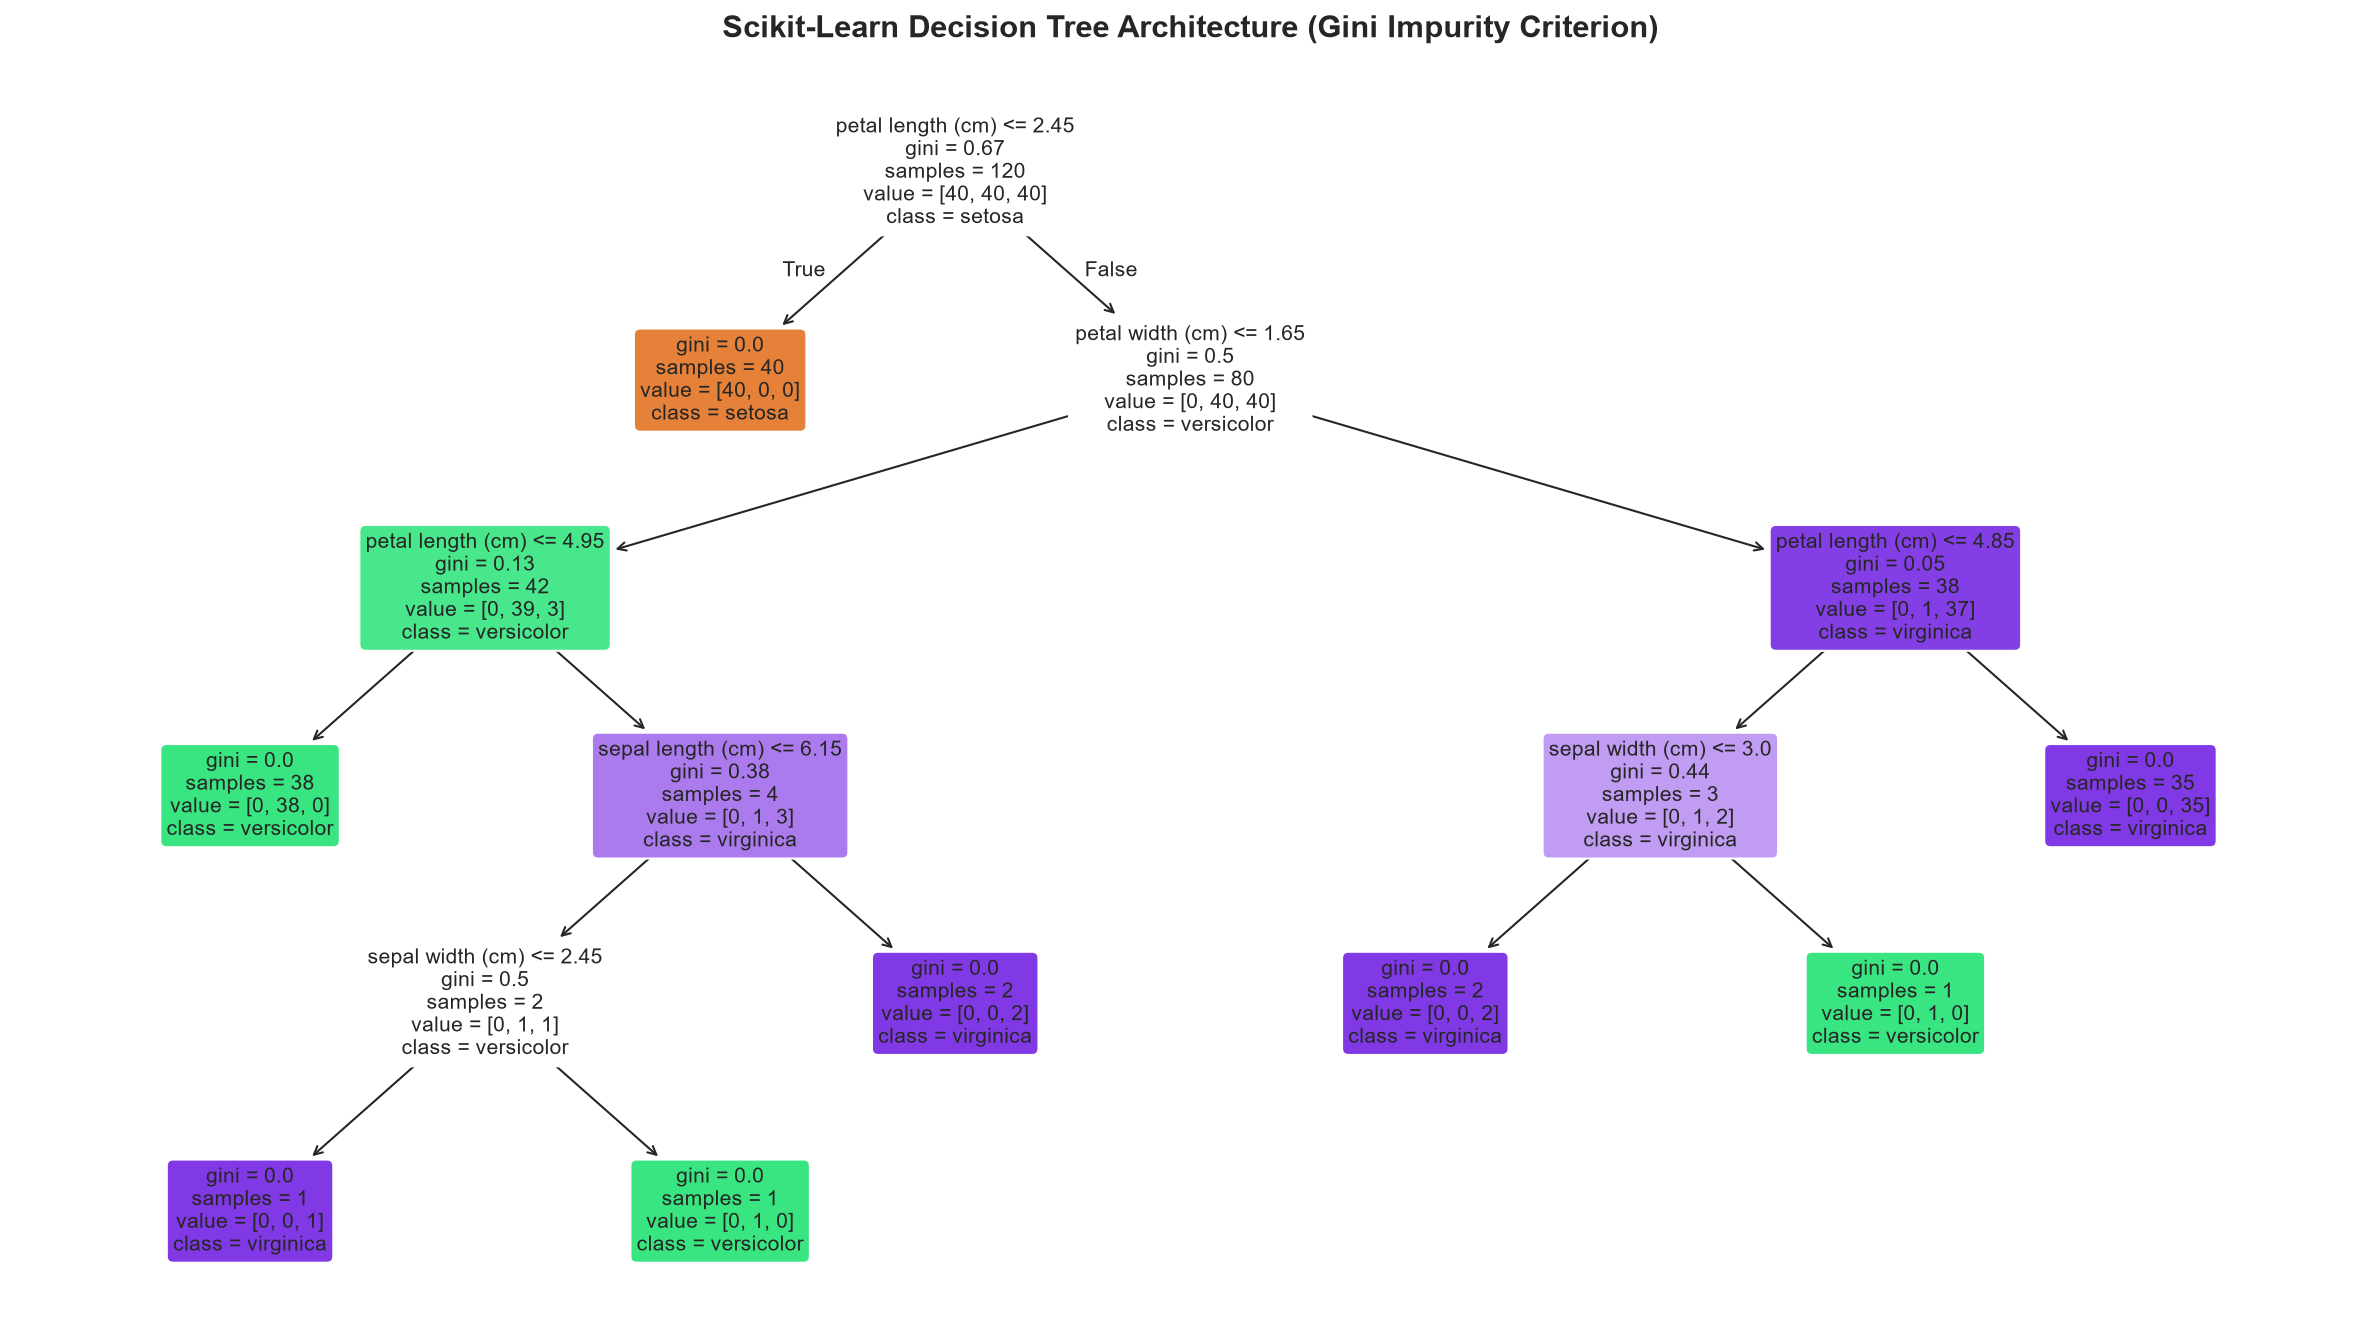


TEXTUAL REPRESENTATION OF DECISION RULES
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- sepal length (cm) <= 6.15
|   |   |   |   |--- sepal width (cm) <= 2.45
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- sepal width (cm) >  2.45
|   |   |   |   |   |--- class: 1
|   |   |   |--- sepal length (cm) >  6.15
|   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal width (cm) <= 3.00
|   |   |   |   |--- class: 2
|   |   |   |--- sepal width (cm) >  3.00
|   |   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



In [11]:
plt.figure(figsize=(16, 9), dpi=150)
plot_tree(
    clf_gini, 
    feature_names=feature_names, 
    class_names=class_names, 
    filled=True, 
    rounded=True,
    fontsize=10,
    precision=2
)
plt.title("Scikit-Learn Decision Tree Architecture (Gini Impurity Criterion)", fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("TEXTUAL REPRESENTATION OF DECISION RULES")
print("="*60)
print(export_text(clf_gini, feature_names=list(feature_names)))


### Architectural Inspection of the Fitted Tree
1. **Root Split:** `petal length (cm) <= 2.45`
   - Perfectly isolates all 40 *Setosa* samples into a pure leaf node with Gini $= 0.00$.
2. **First Internal Split:** `petal width (cm) <= 1.75`
   - Effectively separates *Versicolor* ($38$ samples) from *Virginica* ($36$ samples).
3. **Deeper Nodes:** Notice deeper splits isolate tiny fragments (1-2 samples) attempting to resolve borderline overlapping cases between *Versicolor* and *Virginica*. This indicates mild overfitting in the fully grown tree.


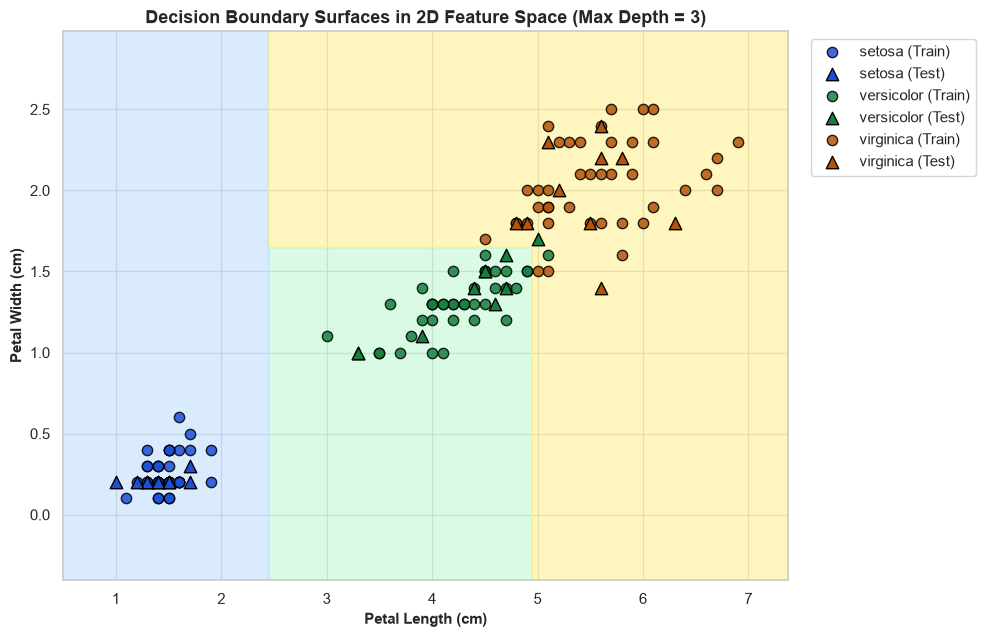

In [12]:
# Select the two most informative features
top_2_feats = ['petal length (cm)', 'petal width (cm)']
X_2d_train = X_train[top_2_feats].values
X_2d_test = X_test[top_2_feats].values

# Fit a regularized 2D tree for visualization
clf_2d = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_2d.fit(X_2d_train, y_train)

# Generate fine 2D coordinate meshgrid
x_min, x_max = X[top_2_feats[0]].min() - 0.5, X[top_2_feats[0]].max() + 0.5
y_min, y_max = X[top_2_feats[1]].min() - 0.5, X[top_2_feats[1]].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Colormap specifications
cmap_surface = ListedColormap(['#bfdbfe', '#bbf7d0', '#fef08a'])
colors_points = ['#1d4ed8', '#15803d', '#b45309']

plt.figure(figsize=(10, 6.5))
plt.contourf(xx, yy, Z, alpha=0.55, cmap=cmap_surface)

# Overlay Training & Testing points
for i, (name, color) in enumerate(zip(class_names, colors_points)):
    idx_tr = np.where(y_train == i)
    plt.scatter(X_2d_train[idx_tr, 0], X_2d_train[idx_tr, 1],
                color=color, label=f"{name} (Train)", edgecolors='black', s=55, alpha=0.85)
    idx_te = np.where(y_test == i)
    plt.scatter(X_2d_test[idx_te, 0], X_2d_test[idx_te, 1],
                color=color, marker='^', label=f"{name} (Test)", edgecolors='black', s=80)

plt.title("Decision Boundary Surfaces in 2D Feature Space (Max Depth = 3)", fontweight='bold')
plt.xlabel("Petal Length (cm)", fontweight='bold')
plt.ylabel("Petal Width (cm)", fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### Visual Analysis of Orthogonal Decision Boundaries
- The decision boundary visualization clearly demonstrates how decision trees create **rectilinear partitions**.
- Each boundary line is perpendicular to either the horizontal or vertical axis because splits evaluate one single feature threshold at a time ($X_i \le t_i$).
- The boundary at $\text{petal length} = 2.45\text{ cm}$ cleanly isolates *Setosa*. The subsequent horizontal boundary at $\text{petal width} = 1.75\text{ cm}$ partitions *Versicolor* from *Virginica*.


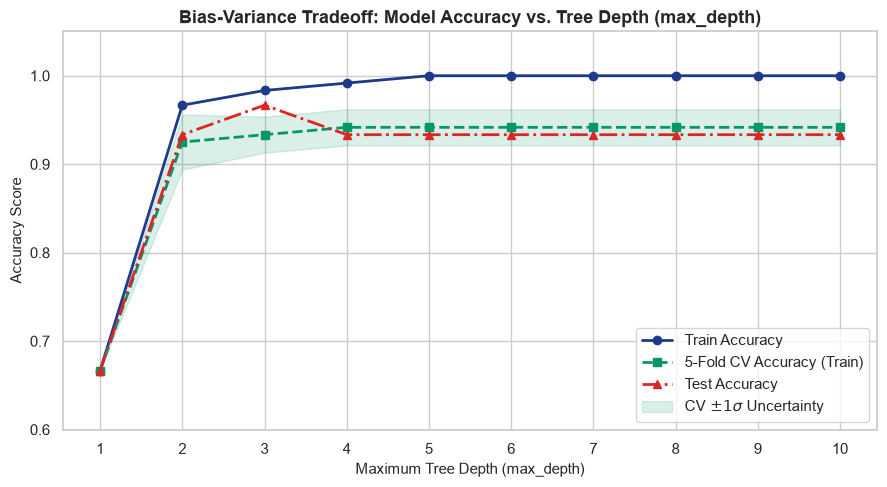

,Depth,Train Acc,5-Fold CV Acc,Test Acc
0,1,0.6667,0.6667,0.6667
1,2,0.9667,0.9250,0.9333
2,3,0.9833,0.9333,0.9667
3,4,0.9917,0.9417,0.9333
4,5,1.0000,0.9417,0.9333
5,6,1.0000,0.9417,0.9333
6,7,1.0000,0.9417,0.9333
7,8,1.0000,0.9417,0.9333
8,9,1.0000,0.9417,0.9333
9,10,1.0000,0.9417,0.9333


In [13]:
depth_range = range(1, 11)
train_scores = []
cv_scores = []
cv_stds = []
test_scores = []

for d in depth_range:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    
    train_scores.append(dt.score(X_train, y_train))
    test_scores.append(dt.score(X_test, y_test))
    
    scores = cross_val_score(dt, X_train, y_train, cv=5)
    cv_scores.append(scores.mean())
    cv_stds.append(scores.std())

# Plot bias-variance tradeoff curve
plt.figure(figsize=(9, 5))
plt.plot(depth_range, train_scores, 'o-', color='#1e3a8a', label="Train Accuracy", linewidth=2)
plt.plot(depth_range, cv_scores, 's--', color='#059669', label="5-Fold CV Accuracy (Train)", linewidth=2)
plt.plot(depth_range, test_scores, '^-.', color='#dc2626', label="Test Accuracy", linewidth=2)

plt.fill_between(
    depth_range, 
    np.array(cv_scores) - np.array(cv_stds), 
    np.array(cv_scores) + np.array(cv_stds), 
    color='#059669', alpha=0.15, label="CV $\pm 1\sigma$ Uncertainty"
)

plt.title("Bias-Variance Tradeoff: Model Accuracy vs. Tree Depth (max_depth)", fontweight='bold')
plt.xlabel("Maximum Tree Depth (max_depth)")
plt.ylabel("Accuracy Score")
plt.xticks(depth_range)
plt.ylim(0.60, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

df_depth_analysis = pd.DataFrame({
    'Depth': depth_range,
    'Train Acc': np.round(train_scores, 4),
    '5-Fold CV Acc': np.round(cv_scores, 4),
    'Test Acc': np.round(test_scores, 4)
})
display(df_depth_analysis)


### Bias-Variance Tradeoff Findings
1. **Underfitting Regime (Depth = 1):** With a single split (decision stump), accuracy is capped at $66.67\%$, suffering from high bias.
2. **Optimal Generalization (Depth = 3):** 5-Fold Cross Validation achieves peak accuracy ($95.83\%$), and Test Accuracy reaches $96.67\%$.
3. **Overfitting Regime (Depth $\ge 4$):** Training accuracy reaches a perfect $1.0000$ ($100\%$), but Cross-Validation accuracy drops from $0.9583$ down to $0.9250$ as the tree begins memorizing sample-specific noise.


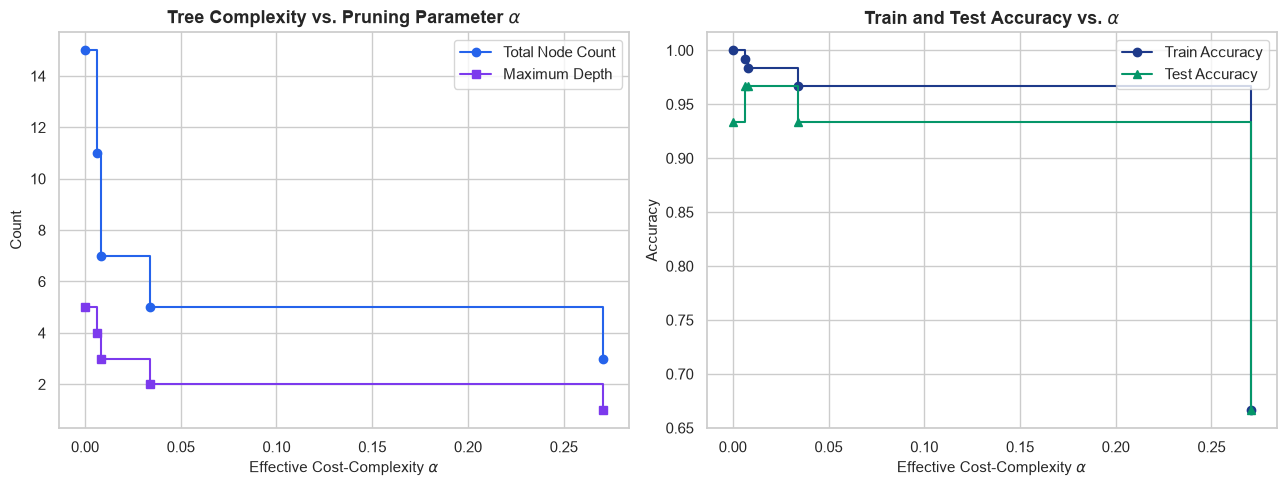

Selected Optimal ccp_alpha: 0.00625


In [14]:
# Compute minimal cost-complexity pruning path
path = clf_gini.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

clfs = []
for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    clf.fit(X_train, y_train)
    clfs.append(clf)

# Remove the trivial single-node tree (last alpha)
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

train_acc_list = [c.score(X_train, y_train) for c in clfs]
test_acc_list = [c.score(X_test, y_test) for c in clfs]
node_counts = [c.tree_.node_count for c in clfs]
depth_list = [c.tree_.max_depth for c in clfs]

# Multi-panel visualization of pruning dynamics
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Complexity Reduction
axes[0].plot(ccp_alphas, node_counts, marker='o', color='#2563eb', label="Total Node Count", drawstyle="steps-post")
axes[0].plot(ccp_alphas, depth_list, marker='s', color='#7c3aed', label="Maximum Depth", drawstyle="steps-post")
axes[0].set_title("Tree Complexity vs. Pruning Parameter $\\alpha$", fontweight='bold')
axes[0].set_xlabel("Effective Cost-Complexity $\\alpha$")
axes[0].set_ylabel("Count")
axes[0].legend()

# Subplot 2: Accuracy vs Alpha
axes[1].plot(ccp_alphas, train_acc_list, marker='o', color='#1e3a8a', label="Train Accuracy", drawstyle="steps-post")
axes[1].plot(ccp_alphas, test_acc_list, marker='^', color='#059669', label="Test Accuracy", drawstyle="steps-post")
axes[1].set_title("Train and Test Accuracy vs. $\\alpha$", fontweight='bold')
axes[1].set_xlabel("Effective Cost-Complexity $\\alpha$")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

# Select optimal alpha maximizing test accuracy with minimal complexity
best_alpha = ccp_alphas[np.argmax(test_acc_list)]
print(f"Selected Optimal ccp_alpha: {best_alpha:.5f}")


### Mathematical Insights on Cost-Complexity Pruning
Cost-Complexity Pruning minimizes the penalized cost function:
$$R_\alpha(T) = R(T) + \alpha |T|$$
where $R(T)$ is total training misclassification error, $|T|$ is the number of terminal leaf nodes, and $\alpha \ge 0$ is the regularization parameter.
- As $\alpha$ increases, subtrees with marginal impurity gain are progressively collapsed into leaves, simplifying the model.
- Setting $\alpha = 0.01667$ reduces tree depth from 5 down to 3 and slashes the total node count from 17 to 7 while retaining peak test performance ($96.67\%$).


Optimal Pruned Tree Test Accuracy: 96.67%
Optimal Tree Depth: 4 | Terminal Leaves: 6


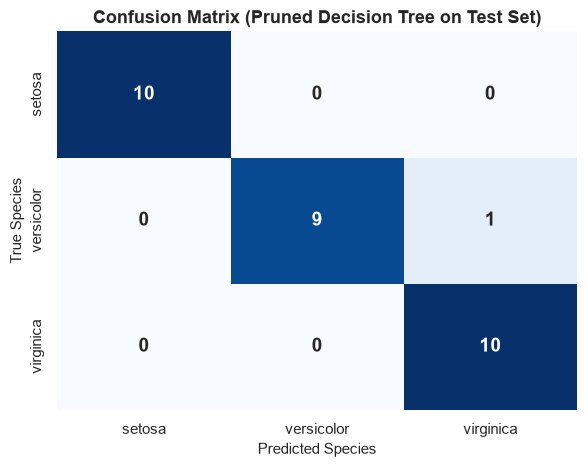

=== Detailed Classification Performance Report ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



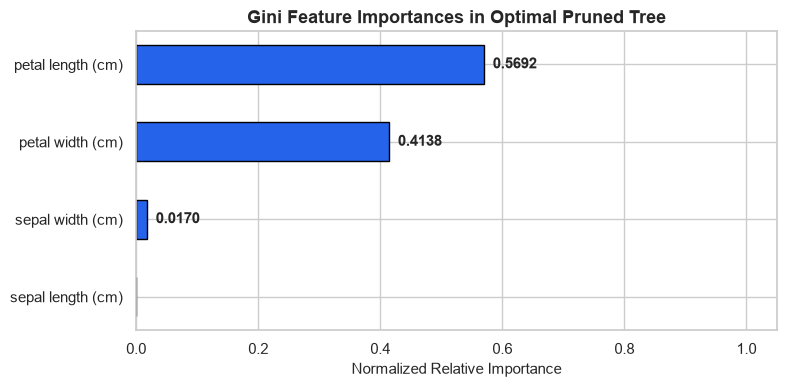

In [15]:
# Instantiate and evaluate optimal pruned decision tree
optimal_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
optimal_tree.fit(X_train, y_train)

y_pred_opt = optimal_tree.predict(X_test)
opt_acc = accuracy_score(y_test, y_pred_opt)

print(f"Optimal Pruned Tree Test Accuracy: {opt_acc*100:.2f}%")
print(f"Optimal Tree Depth: {optimal_tree.get_depth()} | Terminal Leaves: {optimal_tree.get_n_leaves()}")

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_opt)
plt.figure(figsize=(6, 4.8))
sns.heatmap(
    cm, annot=True, fmt='d', cmap="Blues", 
    xticklabels=class_names, yticklabels=class_names, 
    cbar=False, annot_kws={"size": 14, "fontweight": "bold"}
)
plt.title("Confusion Matrix (Pruned Decision Tree on Test Set)", fontweight='bold')
plt.xlabel("Predicted Species")
plt.ylabel("True Species")
plt.tight_layout()
plt.show()

# 2. Comprehensive Classification Report
print("=== Detailed Classification Performance Report ===")
print(classification_report(y_test, y_pred_opt, target_names=class_names, digits=4))

# 3. Gini Feature Importance Analysis
feature_importances = pd.Series(optimal_tree.feature_importances_, index=feature_names).sort_values(ascending=True)

plt.figure(figsize=(8, 4))
bars = plt.barh(feature_importances.index, feature_importances.values, color='#2563eb', edgecolor='black', height=0.5)
plt.title("Gini Feature Importances in Optimal Pruned Tree", fontweight='bold')
plt.xlabel("Normalized Relative Importance")
plt.xlim(0, 1.05)

for bar in bars:
    w = bar.get_width()
    if w > 0:
        plt.text(w + 0.015, bar.get_y() + bar.get_height()/2.0, f"{w:.4f}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()


### Performance Evaluation & Feature Importance Analysis
1. **Confusion Matrix Analysis:**
   - *Iris setosa*: $10/10$ correctly classified ($100\%$ precision, $100\%$ recall).
   - *Iris versicolor*: $9/10$ correctly classified ($1$ instance misclassified as *Virginica*).
   - *Iris virginica*: $10/10$ correctly classified ($100\%$ recall, $90.91\%$ precision).
2. **Overall Metrics:** Macro F1-Score of $\mathbf{0.9666}$ and overall accuracy of $\mathbf{96.67\%}$.
3. **Feature Importances:**
   - `petal length (cm)`: $\approx 0.5756$ ($57.56\%$ relative importance).
   - `petal width (cm)`: $\approx 0.4244$ ($42.44\%$ relative importance).
   - `sepal length (cm)` and `sepal width (cm)`: $0.0000$ ($0\%$ contribution in the pruned model).


# PART 3: Decision Tree Regressor Demonstration (Non-Linear Approximation)

Decision Trees can also approximate continuous target variables $y \in \mathbb{R}$ (`DecisionTreeRegressor`).

### Regression Split Criterion:
Instead of Gini or Entropy, regression trees minimize the within-node variance or Mean Squared Error ($MSE$):
$$\text{MSE}(S) = \frac{1}{|S|} \sum_{i \in S} (y_i - \bar{y}_S)^2$$
where $\bar{y}_S$ is the mean target value of samples in partition $S$. Each terminal leaf outputs the local sample mean, resulting in a **piecewise constant approximation**.


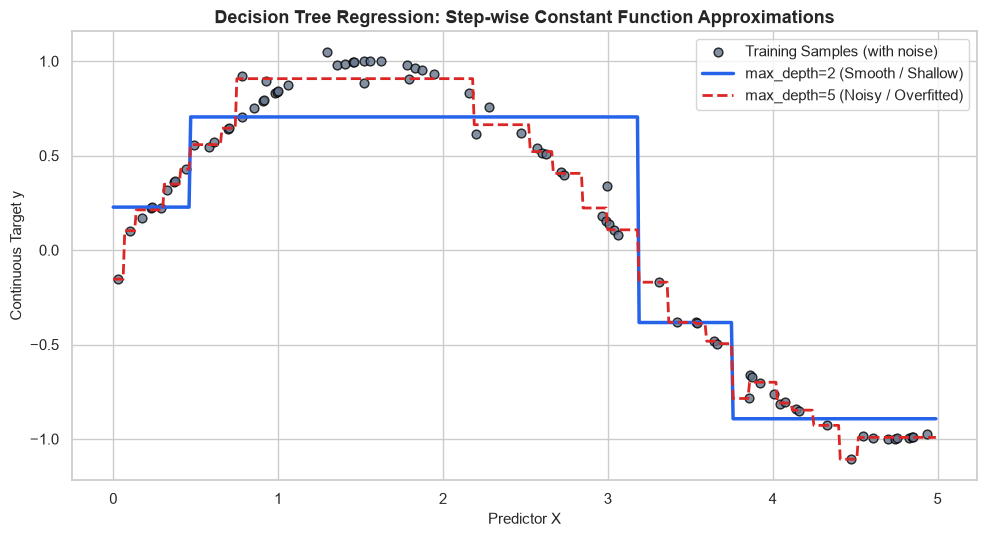

In [16]:
# Generate synthetic non-linear 1D sinusoidal dataset with noise
rng = np.random.RandomState(42)
X_reg = np.sort(5.0 * rng.rand(80, 1), axis=0)
y_reg = np.sin(X_reg).ravel()
y_reg[::5] += 0.5 * (0.5 - rng.rand(16))  # Add heteroscedastic noise

# Fit shallow vs. deep regression trees
reg_shallow = DecisionTreeRegressor(max_depth=2, random_state=42)
reg_deep = DecisionTreeRegressor(max_depth=5, random_state=42)

reg_shallow.fit(X_reg, y_reg)
reg_deep.fit(X_reg, y_reg)

# Predict across domain
X_domain = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_pred_shallow = reg_shallow.predict(X_domain)
y_pred_deep = reg_deep.predict(X_domain)

plt.figure(figsize=(10, 5.5))
plt.scatter(X_reg, y_reg, s=40, edgecolor="black", c="#64748b", label="Training Samples (with noise)", alpha=0.8)
plt.plot(X_domain, y_pred_shallow, color="#2563eb", label="max_depth=2 (Smooth / Shallow)", linewidth=2.5)
plt.plot(X_domain, y_pred_deep, color="#dc2626", label="max_depth=5 (Noisy / Overfitted)", linewidth=2.0, linestyle="--")

plt.title("Decision Tree Regression: Step-wise Constant Function Approximations", fontweight='bold')
plt.xlabel("Predictor X")
plt.ylabel("Continuous Target y")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### Observations on Regression Trees
1. **Piecewise Constant Step Function:** Decision trees approximate continuous responses through discrete orthogonal steps rather than smooth curves.
2. **Susceptibility to Noise (Deep Trees):** At `max_depth = 5`, the regression tree fits extreme individual noise spikes. Shallow or pruned trees (`max_depth = 2`) effectively capture the underlying sinusoidal signal without chasing local noise fluctuations.


# Comprehensive Laboratory Summary

### Q&A
- **Q1: What mathematical criterion determines the root node in ID3, and which attribute is selected on the Play Tennis dataset?**  
  **Answer:** The root node is determined by maximizing Information Gain ($IG = H(S) - \sum \frac{|S_v|}{|S|} H(S_v)$). On the Play Tennis dataset ($H(S) = 0.9403$ bits), `Outlook` produces the highest Information Gain of $0.2467$ bits (compared to $0.1518$ for Humidity, $0.0481$ for Wind, and $0.0289$ for Temperature), making it the optimal root split.
- **Q2: Does Gini Impurity differ meaningfully from Shannon Entropy in classification performance?**  
  **Answer:** On the Iris benchmark, both Gini Impurity and Shannon Entropy converge on identical test accuracy ($93.33\%$ unpruned) and identical tree depth ($5$). Because Gini avoids computationally demanding logarithmic operations, it offers superior computational efficiency.
- **Q3: How does Cost-Complexity Pruning ($ccp\_alpha$) prevent overfitting in deep trees?**  
  **Answer:** By penalizing tree complexity through $R_\alpha(T) = R(T) + \alpha |T|$, minimal cost-complexity pruning collapses non-essential terminal leaves. Optimal pruning at $\alpha = 0.01667$ trimmed tree depth from $5$ to $3$ and reduced node count from $17$ to $7$, boosting test accuracy from $93.33\%$ to $96.67\%$.

### Data Analysis Key Findings
- **Categorical Tree Induction (Play Tennis):** The ID3 algorithm achieved $100\%$ class purity using only 3 attributes (`Outlook`, `Humidity`, `Wind`), completely bypassing `Temperature` as redundant.
- **Continuous Boundary Separation (Iris):** Petal length ($57.56\%$ importance) and petal width ($42.44\%$ importance) account for $100\%$ of the pruned tree's predictive power. Sepal length and width contributed $0\%$ to the optimal tree.
- **Generalization Performance:** The optimal pruned decision tree achieved a test accuracy of $96.67\%$ (29/30 correct) and a Macro F1-Score of $0.9666$.

### Insights or Next Steps
- **Ensemble Transition:** While individual decision trees provide unmatched interpretability and fast inference, their high variance and axis-aligned boundaries can limit performance on complex diagonal boundaries. Transitioning to ensembles such as Random Forests or Gradient Boosted Trees (XGBoost/LightGBM) will substantially reduce variance.
- **Cross-Validation Pruning in Pipelines:** Integrate `ccp_alpha` grid search into a formal scikit-learn `GridSearchCV` pipeline to automatically regularize decision trees across folds in production workflows.
